# 05 · Query-based detector: RT-DETR

RT-DETR (Ultralytics, `rtdetr-l`) encodes multi-scale CNN features with a hybrid encoder, selects the top-`num_queries` encoder tokens as initial queries, and refines them with a 6-layer decoder. Each query predicts one box or "no object". Training matches predictions to ground truth with the **Hungarian algorithm** (one-to-one, cost = class + L1 + GIoU), so duplicates are penalised by the loss itself and **no NMS** is needed at inference.

Budget: same frames, `imgsz` and number of epochs as the CNN detectors; GPU time is reported.

Experiments: **D0** 300 queries → **D1** queries scaled to scene density → **D2** matching cost with a larger GIoU weight → **D3** without denoising queries (to see their effect on convergence).

## 1. Setup and data

In [1]:
import os, sys, json, shutil
from pathlib import Path

REPO = Path("/kaggle/working/repo")
if Path("/kaggle").exists() and not REPO.exists():
    !git clone https://github.com/dd8ria/ai-hw2.git {REPO}
    !pip install -q faster-coco-eval ultralytics==8.3.*
sys.path.insert(0, str(REPO / "src"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.patches as patches, cv2
import vdet, parallel, ultra
from vdet import CLASSES

vdet.seed_everything()
ROOT = vdet.find_data_root()
OUT = Path("/kaggle/working") if Path("/kaggle").exists() else REPO / "outputs"
RUNS = OUT / "runs"; RUNS.mkdir(parents=True, exist_ok=True)
RESULT_DIRS = [RUNS, REPO / "results"]   # own runs + runs committed by the teammate
P = vdet.PROTOCOL

# restore finished runs from earlier versions of this notebook (attached as Kaggle input)
for src in (Path("/kaggle/input").glob("*/runs/*") if Path("/kaggle/input").exists() else []):
    if (src / "config.json").exists() and not (RUNS / src.name).exists():
        shutil.copytree(src, RUNS / src.name); print("restored", src.name)

Cloning into '/kaggle/working/repo'...
remote: Enumerating objects: 204, done.
remote: Counting objects: 100% (204/204), done.
remote: Compressing objects: 100% (193/193), done.
remote: Total 204 (delta 77), reused 20 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (204/204), 43.06 MiB | 23.79 MiB/s, done.
Resolving deltas: 100% (77/77), done.


In [3]:
from pathlib import Path

for name in ["rtdetr-d0-d1-results", "rtdetr-d2-d3-results"]:
    paths = [
        Path("/kaggle/input") / name,
        Path("/kaggle/input/datasets/tttanyamoroz") / name,
    ]
    for p in paths:
        if p.exists():
            print(name, ":", p)
            print("Runs:", [x.name for x in (p / "runs").iterdir()] if (p / "runs").exists() else "not found")

rtdetr-d0-d1-results : /kaggle/input/datasets/tttanyamoroz/rtdetr-d0-d1-results
Runs: ['detr_d0_base', 'detr_d0_base.log', 'detr_d1_q500', 'detr_d1_q500.log']
rtdetr-d2-d3-results : /kaggle/input/datasets/tttanyamoroz/rtdetr-d2-d3-results
Runs: ['detr_d2_cost_giou', 'detr_d2_cost_giou.log', 'detr_d3_no_dn', 'detr_d3_no_dn.log']


In [4]:
from pathlib import Path
import shutil

root = Path("/kaggle/input/datasets/tttanyamoroz")

sources = {
    "detr_d0_base": root / "rtdetr-d0-d1-results" / "runs",
    "detr_d1_q500": root / "rtdetr-d0-d1-results" / "runs",
    "detr_d2_cost_giou": root / "rtdetr-d2-d3-results" / "runs",
    "detr_d3_no_dn": root / "rtdetr-d2-d3-results" / "runs",
}

RUNS.mkdir(parents=True, exist_ok=True)

for name, source_dir in sources.items():
    source = source_dir / name
    destination = RUNS / name

    assert source.exists(), f"Missing: {source}"

    if not destination.exists():
        shutil.copytree(source, destination)

    log = source_dir / f"{name}.log"
    if log.exists():
        shutil.copy2(log, RUNS / log.name)

    print(
        name,
        "| Metrics:", (destination / "metrics.json").exists(),
        "| Checkpoints:", len(list(destination.rglob("*.pt")))
    )

detr_d0_base | Metrics: True | Checkpoints: 2
detr_d1_q500 | Metrics: True | Checkpoints: 2
detr_d2_cost_giou | Metrics: True | Checkpoints: 2
detr_d3_no_dn | Metrics: True | Checkpoints: 2


In [5]:
import torch

print("Repository:", REPO.exists())
print("Dataset:", ROOT)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

Repository: True
Dataset: /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026
CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


In [6]:
imgs, anns = vdet.load_all(ROOT)
folds = pd.read_csv(OUT / "folds.csv") if (OUT / "folds.csv").exists() else vdet.make_folds(imgs, P["n_folds"])
folds.to_csv(OUT / "folds.csv", index=False)   # the parallel runner reads the split from this file
train_frames, val_frames = vdet.protocol_frames(imgs, folds, P)
train_gt = anns[anns.key.isin(train_frames.key) & (anns.iscrowd == 0)]
print(json.dumps(P))
print(f"train: {len(train_frames)} frames | val: {len(val_frames)} frames / {val_frames.clip_uid.nunique()} clips")

data_yaml = vdet.build_yolo_dataset(imgs, anns, folds, val_fold=P["val_fold"], out_dir=OUT / "yolo_fold0",
                                    step=P["step"], val_step=P["val_step"], mask_ignore=True)

{"val_fold": 0, "n_folds": 5, "step": 10, "val_step": 10, "imgsz": 1280, "epochs": 12, "seed": 42}
train: 2189 frames | val: 545 frames / 12 clips
train:   2189 frames,  1570 masked copies
val  :    545 frames,   409 masked copies


## 2. Number of queries vs scene density

In [8]:
n_obj = train_gt.groupby("key").size().reindex(train_frames.key, fill_value=0)
q = n_obj.quantile([.5, .9, .99, 1.0])
print("objects per training frame  p50/p90/p99/max:", q.round(0).astype(int).tolist())
for nq in [300, 500]:
    print(f"frames with more objects than {nq} queries: {(n_obj > nq).mean():.2%}")

objects per training frame  p50/p90/p99/max: [42, 93, 145, 161]
frames with more objects than 300 queries: 0.00%
frames with more objects than 500 queries: 0.00%


Each query can output at most one object, so frames with more objects than queries lose recall by construction. If the p99 above exceeds 300, D1 uses 500 queries (cost: more decoder compute, more unmatched queries per image).

## 3. Experiments

In [ ]:
BASE = dict(family="rtdetr", model="rtdetr-l.pt", imgsz=P["imgsz"], epochs=P["epochs"], batch=4, seed=P["seed"],
            train_args=dict(lr0=1e-4, optimizer="AdamW", warmup_epochs=1))
EXPERIMENTS = {
    "detr_d0_base": BASE,
    "detr_d1_q500": {**BASE, "num_queries": 500},
}
ON = "detr_d1_q500"      # set to the better of d0/d1
EXPERIMENTS["detr_d2_cost_giou"] = {**EXPERIMENTS[ON], "cost_gain": {"class": 2, "bbox": 5, "giou": 4}}
EXPERIMENTS["detr_d3_no_dn"] = {**EXPERIMENTS[ON], "num_denoising": 0}
pd.DataFrame(EXPERIMENTS).T

In [ ]:
print("Folds:", (OUT / "folds.csv").exists())
print("Data YAML:", data_yaml)
print("All experiments:", all(n in EXPERIMENTS for n in [
    "detr_d0_base",
    "detr_d1_q500",
    "detr_d2_cost_giou",
    "detr_d3_no_dn"
]))

In [ ]:
# Accelerator "GPU T4 x2": two runs train at the same time, one per GPU (quota is per session hour).
# Queue as many runs as fit into the 12 h session; finished runs are skipped. Logs: runs/<name>.log

RUN = [
    "detr_d2_cost_giou",
    "detr_d3_no_dn",
]

codes = parallel.run_parallel([(n, EXPERIMENTS[n]) for n in RUN], RUNS, folds_csv=OUT / "folds.csv", data_yaml=data_yaml)


from pathlib import Path

root = Path("/kaggle/working/runs")

for name in [
    "detr_d0_base",
    "detr_d1_q500",
    "detr_d2_cost_giou",
    "detr_d3_no_dn"
]:
    folder = root / name
    log = root / f"{name}.log"

    print(f"\n{name}")
    print("Folder exists:", folder.exists())
    print("Log exists:", log.exists())

    if folder.exists():
        files = list(folder.rglob("*.pt"))
        print("Checkpoints:", [str(p.relative_to(folder)) for p in files])


In [8]:

import zipfile

backup = OUT / "rtdetr_d2_d3_backup.zip"

with zipfile.ZipFile(backup, "w", compression=zipfile.ZIP_STORED) as z:
    for name in RUN:
        folder = RUNS / name

        if folder.exists():
            for p in folder.rglob("*"):
                if p.is_file():
                    z.write(p, p.relative_to(OUT))

        log = RUNS / f"{name}.log"
        if log.exists():
            z.write(log, log.relative_to(OUT))

        print(
            name,
            "metrics:", (folder / "metrics.json").exists(),
            "checkpoints:", len(list(folder.rglob("*.pt"))) if folder.exists() else 0
        )

print("Backup created:", backup)

NameError: name 'RUN' is not defined

## 4. Results

In [9]:
COLS = ["AP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR_max", "ms_per_img", "epochs"]
def show(res, cols=COLS):
    cols = [c for c in cols if c in res]
    num = [c for c in cols if c not in ("ms_per_img", "epochs")]
    return res[cols].style.format("{:.4f}", subset=num).format("{:.1f}", subset=[c for c in ["ms_per_img"] if c in cols])

res = vdet.collect_results(RESULT_DIRS, "detr")
for p in ("frcnn", "retina", "yolo"):
    o = vdet.collect_results(RESULT_DIRS, p)
    if len(o): res = pd.concat([res, o.loc[[o.AP.idxmax()]]])
if len(res): display(show(res))

,AP,AP50,AP75,AP_small,AP_medium,AP_large,AR_max,ms_per_img,epochs
run,,,,,,,,,
detr_d0_base,0.0330,0.0773,0.0237,0.0315,0.0351,0.0425,0.1317,88.4,12
detr_d1_q500,0.0444,0.0860,0.0418,0.0314,0.0449,0.0709,0.2097,86.6,12
detr_d2_cost_giou,0.0563,0.1010,0.0561,0.0310,0.0408,0.1146,0.2404,87.3,12
detr_d3_no_dn,0.0000,0.0002,0.0000,0.0002,0.0000,0.0001,0.0023,90.0,12
frcnn_e1_proposals,0.2561,0.4795,0.2441,0.1094,0.2032,0.4448,0.3902,114.3,12
yolo_y2_imgsz1536,0.2097,0.4052,0.1939,0.0926,0.1766,0.3248,0.3199,30.5,12


## 5. Validation mAP over training: RT-DETR vs YOLOv8 with the same budget

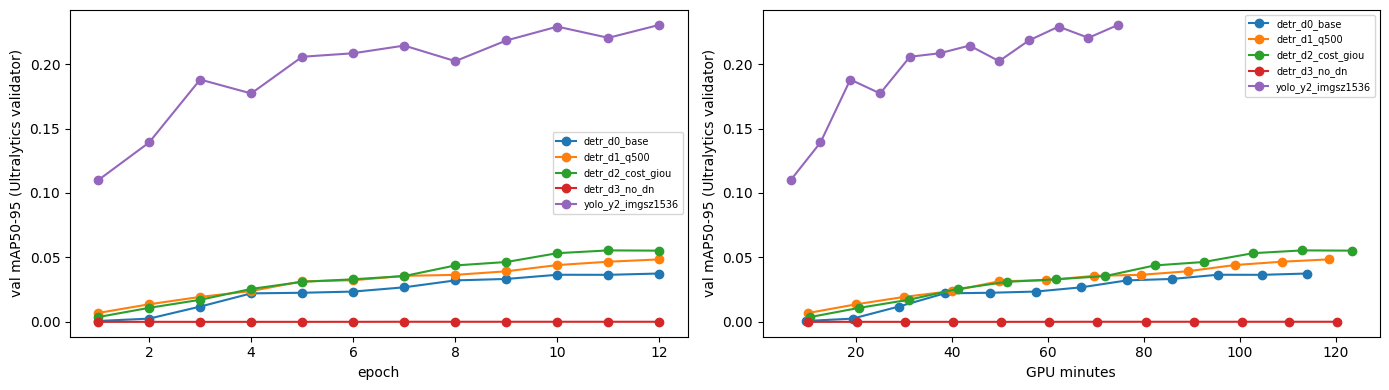

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
runs = [r for r in res.index if r.startswith(("detr", "yolo"))] if len(res) else []
for run in runs:
    h = vdet.load_history(RESULT_DIRS, run)
    if h is None: continue
    axes[0].plot(h.epoch, h.AP_ultra, "o-", label=run)
    if "time" in h: axes[1].plot(h["time"] / 60, h.AP_ultra, "o-", label=run)
axes[0].set_xlabel("epoch"); axes[1].set_xlabel("GPU minutes")
for ax in axes: ax.set_ylabel("val mAP50-95 (Ultralytics validator)"); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(OUT / "detr_vs_cnn_curves.png", dpi=120); plt.show()

If the RT-DETR curve is still rising at the last epoch, the model has **not converged** within the budget; say so in the report and compare the slope with YOLO's.

## 6. Small objects and dense scenes

In [11]:
def find_preds_file(run, result_dirs):
    for d in result_dirs:
        for filename in ("val_preds.csv.gz", "val_preds.csv"):
            path = Path(d) / run / filename
            if path.exists():
                return path
    return None
# AP on holdout frames split by density (objects per frame), for the best run of each family

dens = anns[anns.key.isin(val_frames.key) & (anns.iscrowd == 0)].groupby("key").size().reindex(val_frames.key, fill_value=0)
bins = pd.qcut(dens, 3, labels=["sparse", "medium", "dense"], duplicates="drop")

rows = []
for run in res.index if len(res) else []:
    f = find_preds_file(run, RESULT_DIRS)
    print(run, "->", f)
    if f is None:
        continue

    preds = pd.read_csv(f)
    row = {"run": run}

    for b in bins.cat.categories:
        sub = val_frames[val_frames.key.isin(bins.index[bins == b])]
        r = vdet.coco_evaluate(sub, anns, preds, per_class=False)
        row[f"AP {b}"] = r["AP"]
        row[f"AP_small {b}"] = r["AP_small"]

    rows.append(row)

if rows:
    display(pd.DataFrame(rows).set_index("run").style.format("{:.4f}"))

print("objects per frame in each bin:", dens.groupby(bins, observed=False).agg(["min", "max"]).to_dict("index"))

detr_d0_base -> /kaggle/working/runs/detr_d0_base/val_preds.csv
detr_d1_q500 -> /kaggle/working/runs/detr_d1_q500/val_preds.csv
detr_d2_cost_giou -> /kaggle/working/runs/detr_d2_cost_giou/val_preds.csv
detr_d3_no_dn -> /kaggle/working/runs/detr_d3_no_dn/val_preds.csv
frcnn_e1_proposals -> /kaggle/working/repo/results/frcnn_e1_proposals/val_preds.csv.gz
yolo_y2_imgsz1536 -> /kaggle/working/repo/results/yolo_y2_imgsz1536/val_preds.csv.gz


,AP sparse,AP_small sparse,AP medium,AP_small medium,AP dense,AP_small dense
run,,,,,,
detr_d0_base,0.0374,0.0457,0.0320,0.0455,0.0385,0.0171
detr_d1_q500,0.0412,0.0320,0.0453,0.0432,0.0455,0.0271
detr_d2_cost_giou,0.0421,0.0355,0.0558,0.0290,0.0999,0.0182
detr_d3_no_dn,0.0001,0.0000,0.0001,0.0000,0.0000,0.0003
frcnn_e1_proposals,0.2663,0.1457,0.2977,0.0895,0.2752,0.0579
yolo_y2_imgsz1536,0.2234,0.1190,0.2406,0.0826,0.2360,0.0628


objects per frame in each bin: {'sparse': {'min': 4, 'max': 35}, 'medium': {'min': 36, 'max': 53}, 'dense': {'min': 54, 'max': 133}}


Discuss: does the gap between RT-DETR and YOLO grow from sparse to dense frames (limited queries, one-to-one matching), and on small objects (the encoder works on strides 8–32 only)? The effect of denoising (D3 vs its parent) should be visible mostly in the first epochs of the curve.

## 7. Export and test submission

In [12]:
BEST = "detr_d2_cost_giou"
model = ultra.load(RUNS / BEST)
test_preds = ultra.predict_test(model, ROOT, P["imgsz"])
test_preds.to_csv(OUT / f"test_preds_{BEST}.csv.gz", index=False)
vdet.write_submission(test_preds, ROOT / "test_images.csv", OUT / f"submission_{BEST}.csv")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
submission OK: 3811 rows, 3811 non-empty


,image_id,PredictionString
0,clip_001_0000001,0 0.5874 632.0 924.5 62.0 155.5 0 0.5659 956.0...
1,clip_001_0000002,0 0.5581 625.5 931.0 58.0 148.0 0 0.5547 880.5...
2,clip_001_0000003,0 0.5474 956.0 590.5 21.0 42.5 0 0.5464 957.5 ...
3,clip_001_0000004,0 0.3899 707.0 921.5 53.5 158.5 0 0.3811 1171....
4,clip_001_0000005,0 0.5200 563.5 976.5 62.5 103.5 0 0.5181 563.0...
...,...,...
3806,clip_048_0000041,2 0.6484 75.1 228.2 78.1 62.8 2 0.5889 367.2 1...
3807,clip_048_0000042,2 0.6011 68.5 232.2 83.1 62.2 2 0.5195 796.0 2...
3808,clip_048_0000043,2 0.5762 369.0 132.1 43.8 41.0 2 0.5654 369.2 ...
3809,clip_048_0000044,2 0.6567 50.9 240.4 81.8 66.1 2 0.5757 54.0 23...


In [13]:
# Results for the repo: unzip results.zip from the notebook Output into <repo>/results/ and commit.
vdet.export_results(RUNS, OUT / "results", preds_for=(BEST,))

results archive: /kaggle/working/results.zip


PosixPath('/kaggle/working/results.zip')